# AirfRANS: lift and drag of NACA airfoils from 1000 RANS simulations

**Paper.** Florent Bonnet (Sorbonne Université, CNRS, ISIR; Extrality; Paris, France), Jocelyn Ahmed Mazari
(Extrality; Paris, France), Paola Cinnella (Sorbonne Université, Institut Jean Le Rond d'Alembert; Paris,
France), Patrick Gallinari (Sorbonne Université, CNRS, ISIR; Criteo AI Lab; Paris, France).
"AirfRANS: High Fidelity Computational Fluid Dynamics Dataset for Approximating Reynolds-Averaged
Navier–Stokes Solutions." *Advances in Neural Information Processing Systems 35* (NeurIPS 2022), Datasets
and Benchmarks Track, [doi:10.52202/068431-1705](https://doi.org/10.52202/068431-1705). Page, table and
equation numbers below are those of the arXiv version 3 ([arXiv:2212.07564v3](https://arxiv.org/abs/2212.07564v3),
1 June 2023), a preprint.

Data: AirfRANS, Bonnet et al. 2022, ODbL v1.0 (`DATA.md`).

Notebook: Claude (Anthropic) for P. Constantine, 2026

## Summary

AirfRANS is a set of 1000 steady, incompressible Reynolds-averaged Navier–Stokes simulations (OpenFOAM,
k–ω SST) of the flow around NACA 4- and 5-digit airfoils at Reynolds numbers from 2 to 6 million and angles of
attack from −5° to 15°, made by Bonnet et al. as a benchmark for machine-learning surrogates. This notebook
studies the lift and drag coefficients of the 369 cambered NACA 4-digit airfoils as functions of five inputs
(inlet velocity, angle of attack, maximum camber, camber position, thickness), with the global quadratic
estimator (QPHD), because the simulations give no gradients. Lift has a one-dimensional active subspace
(λ₁/λ₂ = 405.6) whose direction agrees with thin-airfoil theory (|w₁ᵀw₁,theory| = 0.9973, against 0.940 for the angle of attack alone; the camber weights agree, the camber-position weight is 0.56 of the theory's), and drag a
two-dimensional one, led by the angle of attack and then by thickness and camber (λ₁/λ₂ = 40.0,
λ₂/λ₃ = 7.7), on which a cubic reaches leave-one-out R² 0.9787.

## Active subspaces in brief

For a function $f(x)$ of $m$ inputs scaled to $[-1, 1]^m$ with density $\rho$, the active subspace is spanned
by the leading eigenvectors of $C = \int \nabla f\, \nabla f^\top \rho\, dx = W \Lambda W^\top$. A large gap
between eigenvalues $\lambda_n$ and $\lambda_{n+1}$ means $f$ changes mostly along the first $n$ eigenvectors
$W_1$, so $f(x) \approx g(W_1^\top x)$, and a plot of $f$ against the active variables $y = W_1^\top x$
(a sufficient summary plot) shows it. Without gradients, $C$ can be estimated from values only, here by
fitting a global quadratic and averaging the outer product of its gradient. See P. G. Constantine,
[*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860),
SIAM, 2015.

## The model

**Flow equations** (p. 3). Steady incompressible RANS, as printed:

$$\partial_i \bar u_i = 0 \qquad (1)$$

$$\partial_j(\bar u_i \bar u_j) = -\partial_i\left(\frac{\bar p}{\rho}\right) + (\nu + \nu_t)\,\partial^2_{jj} \bar u_i, \quad i \in \{1, 2\} \qquad (2)$$

with the turbulent viscosity $\nu_t$ from the k–ω SST model (Menter et al. 2003; p. 4, Appendix F). Air at
298.15 K and sea level, $\nu = 1.56 \times 10^{-5}$ m²/s (Table 6, p. 21); chord 1 m (footnote 1, p. 4).
Meshes: blockMesh C-grids with the boundaries 200 chords from the airfoil, first cells 2 µm high,
250,000–300,000 cells (p. 4). Solver: OpenFOAM v2112 simpleFoam (SIMPLEC), run until the drag and lift
coefficients converge, on 16 cores of an AMD Threadripper 3960X (pp. 5, 21): about 25 min per simulation and about
20 days for the 1000 (Table 4, p. 9).

**Quantities of interest** (p. 5). The drag and lift coefficients $C_D = D/q_\infty$ and $C_L = L/q_\infty$,
with $q_\infty = \rho U_\infty^2 A/2$ and $A = 1$ m², the force components parallel and normal to the free
stream; each is the sum of a pressure part and a wall-shear-stress part. The paper computes the wall shear
stress with ParaView's gradient filter (p. 6). The coefficients used here were computed from the stored
fields of each case with the force routine of the authors' `airfrans` Python library (pressure at the wall
nodes; wall shear stress from the vtk point gradient of the velocity, with $\nu = 1.5498 \times 10^{-5}$ m²/s,
the library's formula for air at 298.15 K); `DATA.md` gives the details. The viscous part of $C_L$ is below
$10^{-3}$ in every case (printed below) and is too small to be resolved by the force integration (`DATA.md`, "Accuracy"); it is not used.

**Families and the choice of inputs.** Each simulation is an airfoil drawn from Table 1 (p. 4), a Reynolds
number and an angle of attack. A 4-digit airfoil MPXX has maximum camber $M$ (hundredths of chord) at $P$
(tenths of chord) and thickness $XX$ (hundredths of chord); a 5-digit airfoil LPQXX has a camber digit $L$
(design lift coefficient $0.15L$), a camber position $P$ (twentieths of chord) and a switch $Q$ between
standard (0) and reflex (1) camber (pp. 4, 25). The two families have different parameters, so they are
analysed separately. In the 4-digit family $P$ was drawn uniformly on $[0, 7]$ and values below 1.5 were set
to 0 (Table 1 caption; pp. 4, 26), and the paper treats $P = 0$ as a symmetric profile (p. 26): a cambered
airfoil with $P = 1.5$ and a symmetric one with $P = 0$ have no airfoil in between (in the data $M$ has almost
no weight when $P = 0$; see the end). This notebook therefore analyses the **cambered 4-digit airfoils ($P \ge 1.5$)**, on whose five
inputs the design is a box, and repeats the estimate on the $P = 0$ airfoils and on the 5-digit airfoils for
each value of $Q$ at the end.

**Inputs of the main analysis** (m = 5), in the column order of `X` below.

| input | symbol | units | range | source |
|---|---|---|---|---|
| inlet velocity | $U_\infty$ | m/s | [31.2, 93.6] | Re ∈ [2×10⁶, 6×10⁶] (p. 4) times ν = 1.56×10⁻⁵ m²/s (Table 6, p. 21) over the 1 m chord; 93.6 m/s at Re = 6×10⁶ (p. 31) |
| angle of attack | $\alpha$ | deg | [−5, 15] | p. 5 |
| maximum camber | $M$ | % chord | [0, 7] | Table 1, p. 4 |
| camber position | $P$ | tenths of chord | [1.5, 7] here (Table 1: {0} ∪ [1.5, 7]) | Table 1, p. 4 |
| thickness | $XX$ | % chord | [5, 20] | Table 1, p. 4 |

The 5-digit inputs are $L \in [0, 4]$, $P \in [3, 8]$, $Q \in \{0, 1\}$ and $XX \in [5, 20]$ (Table 1). Digits
need not be integers (p. 26).

**Design.** By Table 1's caption, an interval or a set "means that the sampling is uniform over this set";
the text gives the ranges of the Reynolds number and the angle of attack (pp. 4–5) but not their
distribution, and Fig. 4 (p. 27) shows histograms. The public generator code (Extrality/NACA_simulation)
draws every input independently and uniformly, a Monte Carlo design (not a Latin hypercube); the seed is not
reported. The stored angles of attack do not fit that description: there are fewer cases at high incidence
than uniform draws give (tested below), while the other inputs are consistent with uniform draws. The reason
is not known: the code version used for the runs may have sampled differently, or high-incidence runs may
have been dropped or redrawn (the paper says, for its validation study, that runs it could not make converge
are missing from Fig. 9, p. 32). The analysis below nevertheless uses the uniform density on each range, α
included: this is this notebook's choice, matching the stated design, and it means that the high-incidence
corner, where drag curves most, holds fewer samples than that density gives it. The paper does not give the number of 4- and 5-digit
airfoils; the data have 489 and 511. The stored inputs are the numbers in each case's name, rounded to three
decimals. The inlet velocity is used as the input; with ν and the chord fixed it is proportional to the
Reynolds number, so the normalized inputs are the same. Each input is mapped linearly from its range to
[−1, 1] (equivalently, through its uniform CDF).

## Load the data

`airfrans_forces.csv` has one row per simulation: the family, the inputs, the six coefficients and the four
split flags of the archive's `manifest.json` (1 = training set of that split). `airfrans_case_names.txt` has
the case names in the same order.

In [1]:
%matplotlib inline
import os
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
from scipy import stats

SEED = 1705                       # the only seed: every bootstrap below draws from it
t_start = time.perf_counter()

In [2]:
def read(path):
    """Values and column names (units stripped) of this data set's CSV."""
    with open(path) as fh:
        fh.readline()
        cols = fh.readline()[2:].strip().split(',')
    return np.loadtxt(path, delimiter=','), [c.split(' [')[0] for c in cols]


for fn in ('airfrans_forces.csv', 'airfrans_case_names.txt'):
    if not os.path.exists(fn):
        raise FileNotFoundError(f'{fn} is not in this folder: make it from the AirfRANS archive with '
                                'convert_data.py and copy it here (DATA.md, "Running the notebook from the archive").')
D, COLS = read('airfrans_forces.csv')
with open('airfrans_case_names.txt') as fh:
    CASES = [ln.strip() for ln in fh if ln.strip()]
col = {c: D[:, j] for j, c in enumerate(COLS)}
print('airfrans_forces.csv:', D.shape, '  airfrans_case_names.txt:', len(CASES), 'names')
print('columns:', ', '.join(COLS))

airfrans_forces.csv: (1000, 17)   airfrans_case_names.txt: 1000 names
columns: family, U_inf, alpha, M_or_L, P, Q, XX, CD, CD_p, CD_v, CL, CL_p, CL_v, full_train, scarce_train, reynolds_train, aoa_train


## Checks of the data against the paper

In [3]:
fam = col['family']
four = fam == 4
print(f'NACA 4-digit cases {np.sum(four)}, NACA 5-digit cases {np.sum(~four)}')
P4 = col['P'][four]
print(f'4-digit: P = 0 in {np.sum(P4 == 0)} cases; the smallest nonzero P is {P4[P4 > 0].min():.3f}')
print(f'   share of P = 0 among 4-digit cases {np.mean(P4 == 0):.3f}; the Table 1 rule gives 1.5/7 = {1.5 / 7:.3f} '
      f'(binomial sd {np.sqrt(1.5 / 7 * (1 - 1.5 / 7) / len(P4)):.3f})')
print(f"5-digit: Q = 0 in {np.sum(col['Q'][~four] == 0)} cases, Q = 1 in {np.sum(col['Q'][~four] == 1)}")
for lab, mask, names in (('4-digit', four, ['M_or_L', 'P', 'XX']), ('5-digit', ~four, ['M_or_L', 'P', 'XX'])):
    print(f'{lab} ranges: ' + ', '.join(f'{n} {col[n][mask].min():.3f} to {col[n][mask].max():.3f}' for n in names))
a = col['alpha']
print(f'alpha {a.min():.3f} to {a.max():.3f} deg')
NU_T6 = 1.56e-5                   # m^2/s, Table 6 of the paper
NU_LIB = -3.400747e-6 + 3.452139e-8 * 298.15 + 1.00881778e-10 * 298.15**2 - 1.363528e-14 * 298.15**3
U = col['U_inf']
Re = U / NU_T6                    # chord 1 m
print(f'U_inf {U.min():.3f} to {U.max():.3f} m/s -> Re {Re.min():.4g} to {Re.max():.4g} with nu = 1.56e-5')
print(f'with nu = {NU_LIB:.5e} (airfrans): Re {U.min() / NU_LIB:.4g} to {U.max() / NU_LIB:.4g}, '
      f'{np.sum(U / NU_LIB > 6e6)} cases above 6e6')
print(f'ratio of the two viscosities 1.56e-5 / {NU_LIB:.5e} = {NU_T6 / NU_LIB:.4f}')
print('\nsplit flags of manifest.json against the definitions of p. 6:')
print(f"  full_train {int(col['full_train'].sum())} cases; scarce_train {int(col['scarce_train'].sum())}, "
      f"all inside full_train: {bool(np.all(col['full_train'][col['scarce_train'] == 1] == 1))}")
for nu, lab in ((NU_T6, '1.56e-5'), (NU_LIB, f'{NU_LIB:.5e}')):
    r = U / nu
    bad = np.sum((col['reynolds_train'] == 1) != ((r >= 3e6) & (r <= 5e6)))
    print(f'  reynolds_train == (3e6 <= Re <= 5e6) with nu = {lab}: {bad} disagreements')
bad = np.sum((col['aoa_train'] == 1) != ((a >= -2.5) & (a <= 12.5)))
print(f'  aoa_train == (-2.5 <= alpha <= 12.5): {bad} disagreements')
CD_all, CL_all = col['CD'], col['CL']
print(f'\nC_D {CD_all.min():.5f} to {CD_all.max():.5f}; viscous share CD_v/CD of the airfrans split {np.min(col["CD_v"] / CD_all):.3f} '
      f'to {np.max(col["CD_v"] / CD_all):.3f} (median {np.median(col["CD_v"] / CD_all):.3f})')
print(f'C_L {CL_all.min():.4f} to {CL_all.max():.4f}; largest |CL_v| {np.abs(col["CL_v"]).max():.2e}')
print(f'sizes of the parts: CD_p median {np.median(col["CD_p"]):.2e}, below 2e-3 in {np.mean(col["CD_p"] < 2e-3):.2f} '
      f'of the cases; CD_v median {np.median(col["CD_v"]):.2e}; |CL_v| median {np.median(np.abs(col["CL_v"])):.2e}')
print('components add up: max |CD - CD_p - CD_v| = '
      f'{np.abs(CD_all - col["CD_p"] - col["CD_v"]).max():.1e}, max |CL - CL_p - CL_v| = '
      f'{np.abs(CL_all - col["CL_p"] - col["CL_v"]).max():.1e}')

NACA 4-digit cases 489, NACA 5-digit cases 511
4-digit: P = 0 in 120 cases; the smallest nonzero P is 1.526
   share of P = 0 among 4-digit cases 0.245; the Table 1 rule gives 1.5/7 = 0.214 (binomial sd 0.019)
5-digit: Q = 0 in 232 cases, Q = 1 in 279
4-digit ranges: M_or_L 0.006 to 6.998, P 0.000 to 6.992, XX 5.094 to 19.944
5-digit ranges: M_or_L 0.004 to 3.993, P 3.005 to 7.969, XX 5.008 to 19.989
alpha -4.940 to 14.926 deg
U_inf 31.283 to 93.592 m/s -> Re 2.005e+06 to 5.999e+06 with nu = 1.56e-5
with nu = 1.54981e-05 (airfrans): Re 2.018e+06 to 6.039e+06, 6 cases above 6e6
ratio of the two viscosities 1.56e-5 / 1.54981e-05 = 1.0066

split flags of manifest.json against the definitions of p. 6:
  full_train 800 cases; scarce_train 200, all inside full_train: True
  reynolds_train == (3e6 <= Re <= 5e6) with nu = 1.56e-5: 0 disagreements
  reynolds_train == (3e6 <= Re <= 5e6) with nu = 1.54981e-05: 9 disagreements
  aoa_train == (-2.5 <= alpha <= 12.5): 0 disagreements

C_D 0.00690 to

The 1000 cases are 489 NACA 4-digit and 511 5-digit airfoils. 120 of the 4-digit airfoils have $P = 0$, a
share of 0.245 against 0.214 expected from the Table 1 rule (binomial sd 0.019). All inputs lie in the
paper's ranges. With ν = 1.56×10⁻⁵ m²/s (Table 6) the inlet velocities give Re from 2.005×10⁶ to
5.999×10⁶, and the `reynolds_train` flags agree with the definition "Reynolds of three to five million"
(p. 6) for every case; with the `airfrans` value of ν there would be 6 cases above 6×10⁶ and 9 disagreeing
flags. So the inlet velocities were set with ν = 1.56×10⁻⁵ m²/s. The archive does not record which value the
solver used; the wall shear stress behind these coefficients is computed with the library's value, and if the
solver used 1.56×10⁻⁵ the viscous parts would be low by the printed ratio of the two values, 1.0066. The other
split flags also match p. 6. The
pressure and viscous parts add up to the totals to rounding (differences of order 1e-16 and below). In the
split computed by `airfrans` the viscous part is 0.071 to 0.936 of $C_D$ (median 0.686). That split depends on
how the wall pressure and the wall velocity gradient are discretized (an independent integration moves part of
$C_D$ from one part to the other; `DATA.md`, "Accuracy"), so it describes these post-processed values rather
than the flow alone; the totals $C_D$ and $C_L$, which the analysis uses, agree between the two methods. The
viscous part of $C_L$ is at most 6.35e-04 in absolute value and is not resolved.

## The cambered NACA 4-digit airfoils

Rule: keep the 4-digit rows with $P > 0$ (all have $P \ge 1.5$).

In [4]:
NAMES = ['U_inf', 'alpha', 'M', 'P', 'XX']
LABELS = [r'$U_\infty$', r'$\alpha$', '$M$', '$P$', '$XX$']
LO = [31.2, -5.0, 0.0, 1.5, 5.0]       # U_inf = Re nu / c for Re in [2e6, 6e6], nu = 1.56e-5, c = 1 m
HI = [93.6, 15.0, 7.0, 7.0, 20.0]
sel = four & (col['P'] > 0)            # cambered NACA 4-digit airfoils: P in [1.5, 7]
X = np.column_stack([col[c][sel] for c in ['U_inf', 'alpha', 'M_or_L', 'P', 'XX']])
QOIS = {'CL': col['CL'][sel], 'CD': col['CD'][sel]}
QLAB = {'CL': '$C_L$', 'CD': '$C_D$'}
space = ac.Uniform(LO, HI, names=NAMES)
Z = space.to_normalized(X)
Mrows, m = X.shape
print(f'cambered 4-digit subset: M = {Mrows} cases, m = {m} inputs')
print('normalized inputs inside [-1, 1]:', bool(np.all(np.abs(Z) <= 1)),
      '; per-input min/max of the normalized samples:',
      ', '.join(f'{n} [{Z[:, i].min():+.3f}, {Z[:, i].max():+.3f}]' for i, n in enumerate(NAMES)))
print(f'mean / sd of the normalized samples (uniform: 0 / {1 / np.sqrt(3):.3f}): '
      + ', '.join(f'{n} {Z[:, i].mean():+.3f} / {Z[:, i].std():.3f}' for i, n in enumerate(NAMES)))

cambered 4-digit subset: M = 369 cases, m = 5 inputs
normalized inputs inside [-1, 1]: True ; per-input min/max of the normalized samples: U_inf [-0.997, +0.997], alpha [-0.991, +0.984], M [-0.998, +0.999], P [-0.991, +0.997], XX [-0.987, +0.991]
mean / sd of the normalized samples (uniform: 0 / 0.577): U_inf +0.011 / 0.591, alpha -0.072 / 0.552, M -0.009 / 0.580, P -0.037 / 0.583, XX -0.051 / 0.561


In [5]:
# The realized design: each input against independent uniform draws on its stated range
# (Kolmogorov-Smirnov and Cramer-von Mises tests), and the angle of attack in 2.5-degree bins.
a = col['alpha']
cnt = np.histogram(a, bins=np.arange(-5, 15.01, 2.5))[0]
sd_bin = np.sqrt(1000 * 0.125 * 0.875)
print('alpha, all 1000 cases, counts in 2.5-deg bins from -5 to 15 deg:', cnt,
      f'(uniform: 125 each, sd {sd_bin:.1f})')
n_hi = int(np.sum(a > 12.5))
print(f'alpha > 12.5 deg: {n_hi} cases (uniform: 125, z = {(n_hi - 125) / sd_bin:+.1f}); '
      f'alpha < -2.5 deg: {np.sum(a < -2.5)} cases')
k = int(col['aoa_train'].sum())
print(f'aoa_train (-2.5 <= alpha <= 12.5): {k} of 1000 (uniform: 750; binomial p = '
      f'{stats.binomtest(k, 1000, 0.75).pvalue:.1e})')
z = 2 * (a + 5) / 20 - 1
print(f'normalized alpha, all 1000 cases: mean {z.mean():+.3f}, sd {z.std():.3f} (uniform: 0, {1 / np.sqrt(3):.3f})')
tests = [('alpha, all 1000', a, -5, 15), ('U_inf, all 1000', col['U_inf'], 31.2, 93.6),
         ('XX, all 1000', col['XX'], 5, 20)]
tests += [(f'{n}, cambered 4-digit', X[:, i], LO[i], HI[i]) for i, n in enumerate(NAMES)]
tests += [('L, 5-digit', col['M_or_L'][~four], 0, 4), ('P, 5-digit', col['P'][~four], 3, 8)]
print('tests against uniform on the stated range:')
for lab, v, lo, hi in tests:
    u = (v - lo) / (hi - lo)
    print(f'  {lab:22s} KS p {stats.kstest(u, "uniform").pvalue:.3f}, '
          f'CvM p {stats.cramervonmises(u, "uniform").pvalue:.3f}')
hi_a = a > 11
mw = [('M (4-digit)', col['M_or_L'], four), ('L (5-digit)', col['M_or_L'], ~four),
      ('XX', col['XX'], fam > 0), ('U_inf', col['U_inf'], fam > 0)]
print('alpha > 11 deg against alpha <= 11 deg, Mann-Whitney p: '
      + ', '.join(f'{lab} {stats.mannwhitneyu(v[hi_a & mk], v[~hi_a & mk]).pvalue:.2f}' for lab, v, mk in mw))

alpha, all 1000 cases, counts in 2.5-deg bins from -5 to 15 deg: [111 154 138 133 126 136 117  85] (uniform: 125 each, sd 10.5)
alpha > 12.5 deg: 85 cases (uniform: 125, z = -3.8); alpha < -2.5 deg: 111 cases
aoa_train (-2.5 <= alpha <= 12.5): 804 of 1000 (uniform: 750; binomial p = 5.8e-05)
normalized alpha, all 1000 cases: mean -0.047, sd 0.547 (uniform: 0, 0.577)
tests against uniform on the stated range:
  alpha, all 1000        KS p 0.007, CvM p 0.003
  U_inf, all 1000        KS p 0.812, CvM p 0.904
  XX, all 1000           KS p 0.534, CvM p 0.623
  U_inf, cambered 4-digit KS p 0.792, CvM p 0.857
  alpha, cambered 4-digit KS p 0.008, CvM p 0.014
  M, cambered 4-digit    KS p 0.890, CvM p 0.965
  P, cambered 4-digit    KS p 0.184, CvM p 0.239
  XX, cambered 4-digit   KS p 0.187, CvM p 0.117
  L, 5-digit             KS p 0.020, CvM p 0.172
  P, 5-digit             KS p 0.248, CvM p 0.269
alpha > 11 deg against alpha <= 11 deg, Mann-Whitney p: M (4-digit) 0.32, L (5-digit) 0.87, XX 0

The angle of attack is the input that departs from uniform draws: the counts in 2.5° bins fall to 117 and
85 in the two highest bins, 85 cases lie above 12.5° against 125 expected (z = −3.8), the
angle-of-attack training set holds 804 cases against 750 (binomial p = 5.8e-05), and the tests give p = 0.007
(KS) and 0.003 (Cramér–von Mises) over all 1000 cases and 0.008 and 0.014 in the cambered subset, whose
normalized α has mean −0.072 and sd 0.552 (uniform: 0, 0.577). The inlet velocity, camber, camber position and
thickness are consistent with uniform draws (KS p from 0.184 to 0.890); the 5-digit camber digit $L$ gives KS p 0.020
but Cramér–von Mises p 0.172, marginal among the ten inputs tested. The cases above 11° do not differ in camber,
thickness or inlet velocity from the rest (Mann–Whitney p 0.17 to 0.94), so the shortfall is in α alone. As
stated above, the analysis keeps the uniform density on [−5°, 15°] for α; the reason for the shortfall is
listed as unknown in `DATA.md`.

## Estimate the subspace

The simulations give values only. With $m = 5$ the global quadratic in the normalized inputs has 21
coefficients, against $M = 369$ cases, so **QPHD** is used: fit
$q(x) = c + g^\top x + \tfrac12 x^\top H x$ by least squares and take
$C = \mathbb{E}[\nabla q \nabla q^\top] = g g^\top + H \Sigma H$, with $\Sigma = I/3$ the covariance of the
uniform density on $[-1, 1]^5$ (the density chosen above for every input, α included): the active-subspace matrix of the fitted quadratic. The library warns that on
a uniform space this is not the gradient average of the model itself (that holds for Gaussian inputs), so two
checks follow: the OLS direction (the gradient of the least-squares linear fit) and the active subspace of a
least-squares cubic (56 coefficients). The bootstrap uses 500 replicates. Signs: $w_1$ has a positive
angle-of-attack entry and $w_2$ a positive thickness entry (the paper has no active-subspace figures).

In [6]:
def estimate(**kw):
    """ac.active_subspace from values (QPHD or OLS). On a uniform space the library warns that these are not
    gradient averages of the model itself (see the text above); that warning is silenced for these calls only."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ac.ValidityWarning)
        return ac.active_subspace(**kw)


REF = np.zeros((m, 2))
REF[1, 0] = 1.0                        # sign rule: w1 has a positive alpha entry,
REF[4, 1] = 1.0                        # w2 a positive thickness (XX) entry
QP, OL = {}, {}
for q, f in QOIS.items():
    s = estimate(space=space, X=X, f=f, estimator='qphd', n=2, nboot=500, bootstrap_vectors=2,
                           rng=SEED, qoi=q)
    QP[q] = ac.orient(s, by='reference', reference=REF, columns=2)
    s = estimate(space=space, X=X, f=f, estimator='ols', n=1, nboot=500, bootstrap_vectors=1,
                           rng=SEED, qoi=q)
    OL[q] = ac.orient(s, by='reference', reference=REF[:, :1], columns=1)
for q in QOIS:
    s = QP[q]
    ev = s.eigenvalues
    be = s.bootstrap_eigenvalues
    print(f'{q}  QPHD eigenvalues:', np.array2string(ev, precision=3))
    rat = ev[:-1] / ev[1:]
    brat = be[:, :-1] / be[:, 1:]
    lo_, hi_ = np.percentile(brat, [2.5, 97.5], axis=0)
    print('     ratios lambda_k/lambda_k+1:', ', '.join(f'{r:.1f} [{l:.1f}, {h:.1f}]' for r, l, h in zip(rat, lo_, hi_)),
          ' (bootstrap 2.5-97.5 %)')
    dist = s.bootstrap_distances
    print('     mean bootstrap subspace distance, k = 1..4:', np.array2string(dist.mean(0), precision=3))
    print(f'     share of the eigenvalue sum outside the first k: k=1 {1 - ev[0] / ev.sum():.4f}, '
          f'k=2 {1 - ev[:2].sum() / ev.sum():.4f}')
    for j in range(2):
        w = s.W[:, j]
        bw = s.bootstrap_eigenvectors[:, :, j]
        lo_, hi_ = np.percentile(bw, [2.5, 97.5], axis=0)
        print(f'     w{j + 1}: ' + ', '.join(f'{n} {w[i]:+.3f} [{lo_[i]:+.2f}, {hi_[i]:+.2f}]' for i, n in enumerate(NAMES)))
    wo = OL[q].W[:, 0]
    print(f'     OLS w1: ' + ', '.join(f'{n} {wo[i]:+.3f}' for i, n in enumerate(NAMES))
          + f';  |w1(QPHD) . w1(OLS)| = {abs(wo @ s.W[:, 0]):.4f}; OLS bootstrap mean distance '
          f'{OL[q].bootstrap_distances[:, 0].mean():.3f}')

CL  QPHD eigenvalues: [1.087e+00 2.681e-03 1.778e-03 6.128e-04 1.438e-04]
     ratios lambda_k/lambda_k+1: 405.6 [329.0, 470.7], 1.5 [1.3, 2.1], 2.9 [1.8, 4.2], 4.3 [1.9, 11.8]  (bootstrap 2.5-97.5 %)
     mean bootstrap subspace distance, k = 1..4: [0.003 0.209 0.111 0.138]
     share of the eigenvalue sum outside the first k: k=1 0.0048, k=2 0.0023
     w1: U_inf +0.014 [+0.01, +0.02], alpha +0.940 [+0.94, +0.94], M +0.333 [+0.33, +0.34], P +0.056 [+0.05, +0.06], XX -0.051 [-0.05, -0.05]
     w2: U_inf -0.260 [-0.35, -0.15], alpha +0.146 [+0.06, +0.22], M -0.202 [-0.41, +0.03], P -0.441 [-0.72, -0.14], XX +0.822 [+0.51, +0.95]
     OLS w1: U_inf +0.018, alpha +0.938, M +0.338, P +0.059, XX -0.040;  |w1(QPHD) . w1(OLS)| = 0.9999; OLS bootstrap mean distance 0.007
CD  QPHD eigenvalues: [1.730e-04 4.321e-06 5.642e-07 5.027e-07 4.013e-08]
     ratios lambda_k/lambda_k+1: 40.0 [28.7, 54.9], 7.7 [3.1, 11.0], 1.1 [1.1, 5.9], 12.5 [1.1, 224.7]  (bootstrap 2.5-97.5 %)
     mean bootstrap subs

**Lift.** The first QPHD eigenvalue of $C_L$ is 405.6 times the second (bootstrap 2.5–97.5 %: 329.0 to
470.7), and the eigenvalues outside the first hold 0.0048 of the sum. The first eigenvector, $\alpha$ +0.940,
$M$ +0.333, $P$ +0.056, $XX$ −0.051, $U_\infty$ +0.014, has a mean bootstrap subspace distance of 0.003; the
OLS direction agrees with it (|w₁ᵀw₁,OLS| = 0.9999). The second eigenvector is not determined
(λ₂/λ₃ = 1.5, distance 0.209).

**Drag.** For $C_D$, λ₁/λ₂ = 40.0 [28.7, 54.9] and λ₂/λ₃ = 7.7 [3.1, 11.0], with 0.0304 of the eigenvalue
sum outside the first eigenvector and 0.0062 outside the first two. $w_1$ is again led by the angle of attack
($\alpha$ +0.967, $M$ +0.214, $U_\infty$ −0.114, $XX$ +0.064, $P$ +0.037); $w_2$ is led by thickness and
camber ($XX$ +0.844, $M$ +0.433, $U_\infty$ −0.220, $\alpha$ −0.183, $P$ +0.136). The mean bootstrap
distances are 0.025 for $w_1$ and 0.091 for the two-dimensional subspace. The negative $U_\infty$ entries say
that drag falls as the Reynolds number rises (thinner boundary layers, lower skin friction).

### Check: the active subspace of a cubic

In [7]:
# A check of the quadratic's directions: gradients of a least-squares cubic in all five inputs
# (56 coefficients), evaluated at the 369 samples, in the gradient-based estimator.
CUB = {}
for q, f in QOIS.items():
    sur = ac.fit_surrogate(X=X, f=f, space=space, subspace=None, kind='poly', degree=3, qoi=q)
    G = ac.predict_gradient(sur, X)
    s = ac.active_subspace(space=space, grads=G, n=2, qoi=q)
    CUB[q] = ac.orient(s, by='reference', reference=REF, columns=2)
    ev = CUB[q].eigenvalues
    W, Wq = CUB[q].W, QP[q].W
    print(f'{q}: sd over the {Mrows} cases {f.std(ddof=1):.2e}; cubic LOO RMS error '
          f'{np.sqrt((1 - sur.loo_r_squared) * f.var()):.2e}')
    print(f'{q}: cubic LOO R^2 {sur.loo_r_squared:.4f}; eigenvalue ratios '
          + ', '.join(f'{r:.1f}' for r in ev[:-1] / ev[1:])
          + f'; |w1 . w1(QPHD)| = {abs(W[:, 0] @ Wq[:, 0]):.4f}; 2-D subspace distance to QPHD '
          f'{np.linalg.norm(W[:, :2].T @ Wq[:, 2:], 2):.3f}')
    print('     w1: ' + ', '.join(f'{n} {W[i, 0]:+.3f}' for i, n in enumerate(NAMES))
          + ';  w2: ' + ', '.join(f'{n} {W[i, 1]:+.3f}' for i, n in enumerate(NAMES)))

CL: sd over the 369 cases 5.80e-01; cubic LOO RMS error 7.74e-03
CL: cubic LOO R^2 0.9998; eigenvalue ratios 323.2, 1.5, 2.1, 4.7; |w1 . w1(QPHD)| = 1.0000; 2-D subspace distance to QPHD 0.286
     w1: U_inf +0.015, alpha +0.939, M +0.336, P +0.056, XX -0.044;  w2: U_inf -0.194, alpha +0.071, M -0.020, P -0.276, XX +0.938
CD: sd over the 369 cases 5.39e-03; cubic LOO RMS error 6.75e-04
CD: cubic LOO R^2 0.9843; eigenvalue ratios 25.0, 9.2, 1.3, 3.2; |w1 . w1(QPHD)| = 0.9990; 2-D subspace distance to QPHD 0.153
     w1: U_inf -0.111, alpha +0.973, M +0.193, P +0.059, XX +0.031;  w2: U_inf -0.094, alpha -0.140, M +0.490, P +0.076, XX +0.852


The cubic fits better (LOO R² 0.9998 for $C_L$, 0.9843 for $C_D$) and gives the same leading directions:
|w₁ᵀw₁,QPHD| = 1.0000 for lift and 0.9990 for drag, and a distance of 0.153 between the two-dimensional drag
subspaces of the cubic and of QPHD. Its eigenvalue ratios for drag are 25.0 and 9.2. The second lift
direction differs between the two fits (distance 0.286), as expected for an eigenvalue ratio near 1.

## Results

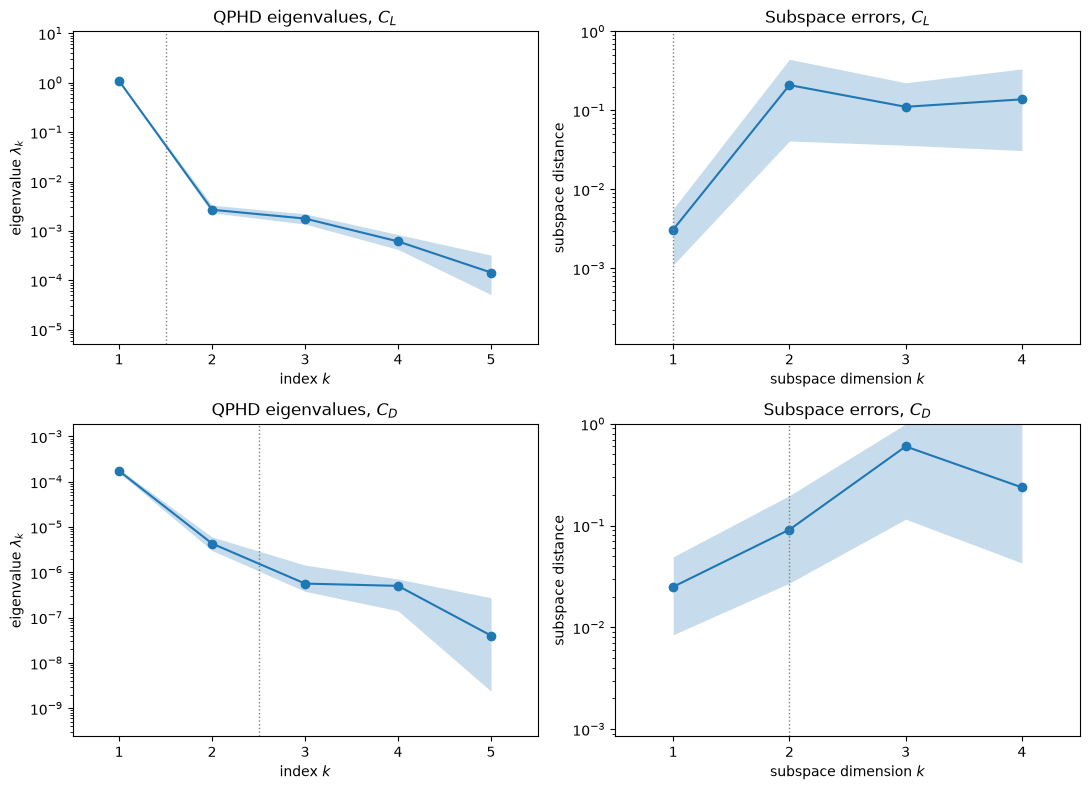

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for r, q in enumerate(QOIS):
    s = ac.with_dimension(QP[q], 1 if q == 'CL' else 2)     # the dimensions chosen below
    ac.plotting.plot_eigenvalues(s, ax=axes[r, 0])
    axes[r, 0].set_title(f'QPHD eigenvalues, {QLAB[q]}')
    ac.plotting.plot_subspace_errors(s, ax=axes[r, 1])
    axes[r, 1].set_title(f'Subspace errors, {QLAB[q]}')
fig.tight_layout()
plt.close(fig)
fig

Eigenvalues with 95 % bootstrap bands (left) and the mean bootstrap subspace distance (right); the dotted
line marks the dimension chosen below. For lift the eigenvalues drop by a factor of 405.6 after the first and then decrease
slowly, and the subspace error rises from 0.003 at $k = 1$ to 0.209 at $k = 2$. For drag the error stays below 0.1 up to
$k = 2$ and jumps to 0.6 at $k = 3$, where λ₃/λ₄ = 1.1.

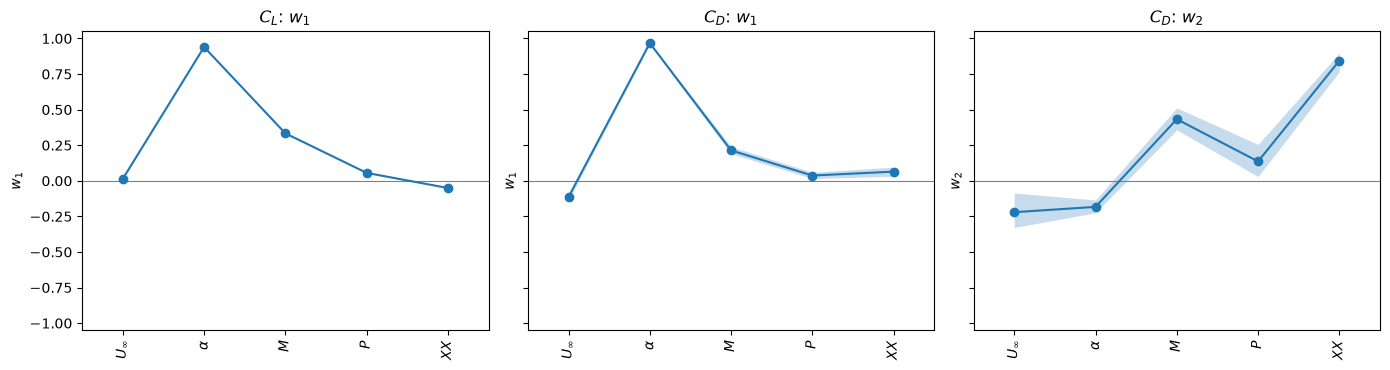

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
ac.plotting.plot_eigenvectors(QP['CL'], indices=[0], labels=LABELS, interval='percentile', ax=[axes[0]])
axes[0].set_title(r'$C_L$: $w_1$')
ac.plotting.plot_eigenvectors(QP['CD'], indices=[0], labels=LABELS, interval='percentile', ax=[axes[1]])
ac.plotting.plot_eigenvectors(QP['CD'], indices=[1], labels=LABELS, interval='percentile', ax=[axes[2]])
axes[1].set_title(r'$C_D$: $w_1$')
axes[2].set_title(r'$C_D$: $w_2$')
fig.tight_layout()
plt.close(fig)
fig

Eigenvectors with 95 % bootstrap bands. Lift and drag share the angle-of-attack-plus-camber direction;
lift weighs camber more (+0.333 against +0.214) and is nearly blind to inlet velocity and thickness. The second
drag direction is mostly thickness, with camber of the same sign.

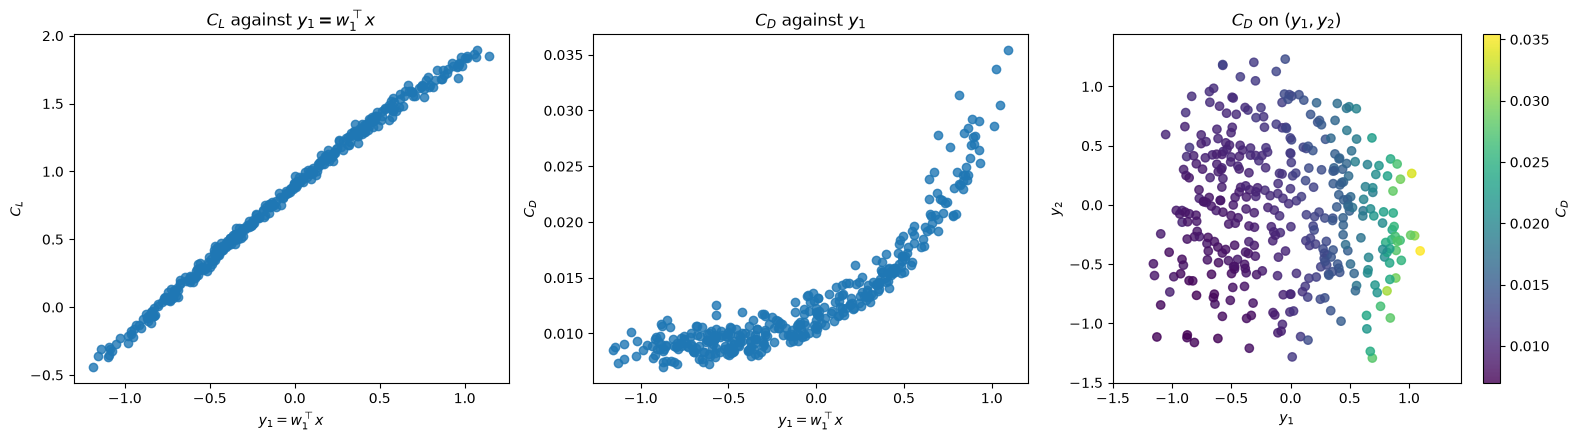

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ac.plotting.plot_sufficient_summary(ac.with_dimension(QP['CL'], 1), X=X, f=QOIS['CL'], qoi_label='$C_L$', ax=axes[0])
axes[0].set_title(r'$C_L$ against $y_1 = w_1^\top x$')
ac.plotting.plot_sufficient_summary(ac.with_dimension(QP['CD'], 1), X=X, f=QOIS['CD'], qoi_label='$C_D$', ax=axes[1])
axes[1].set_title(r'$C_D$ against $y_1$')
ac.plotting.plot_sufficient_summary(QP['CD'], X=X, f=QOIS['CD'], qoi_label='$C_D$', ax=axes[2])
axes[2].set_title(r'$C_D$ on $(y_1, y_2)$')
fig.tight_layout()
plt.close(fig)
fig

Sufficient summary plots. $C_L$ is close to linear in $y_1$ over its whole range. $C_D$ against $y_1$
looks like a drag polar (since $y_1$ is nearly proportional to $C_L$): flat near its minimum and rising steeply at large $y_1$ (high angle of attack and
camber), with a vertical spread that the second variable explains in part (right panel).

## Choosing the dimension: how well do the active variables predict?

LOO R² of polynomials of degree 2 and 3 in the first $n$ active variables (the full-data subspace held fixed),
and 10-fold cross-validated R² with the QPHD subspace re-estimated on each training fold. The last row of each
quantity uses all five inputs.

In [11]:
# Leave-one-out R^2 of polynomials of degree 2 and 3 in the first n active variables of the full-data
# QPHD subspace (the subspace is held fixed in each fold), and 10-fold cross-validated R^2 with the
# subspace re-estimated by QPHD on each training fold.
def cv_r2(f, n, deg, folds=10):
    rng = np.random.default_rng(SEED)
    part = np.array_split(rng.permutation(Mrows), folds)
    pred = np.empty(Mrows)
    for test in part:
        train = np.setdiff1d(np.arange(Mrows), test)
        if n is None:
            sur = ac.fit_surrogate(X=X[train], f=f[train], space=space, subspace=None, kind='poly', degree=deg)
        else:
            s = estimate(space=space, X=X[train], f=f[train], estimator='qphd', n=n)
            sur = ac.fit_surrogate(X=X[train], f=f[train], subspace=s, kind='poly', degree=deg)
        pred[test] = ac.predict(sur, X[test])
    return 1 - np.sum((f - pred)**2) / np.sum((f - f.mean())**2)


LOO = {}
print(f"{'QoI':4s} {'variables':>16s} {'LOO deg 2':>10s} {'LOO deg 3':>10s} {'10-fold deg 2':>14s} {'10-fold deg 3':>14s}")
for q, f in QOIS.items():
    for n in (1, 2, 3, None):
        row = []
        for deg in (2, 3):
            if n is None:
                sur = ac.fit_surrogate(X=X, f=f, space=space, subspace=None, kind='poly', degree=deg)
            else:
                sur = ac.fit_surrogate(X=X, f=f, subspace=ac.with_dimension(QP[q], n), kind='poly', degree=deg)
            row.append(sur.loo_r_squared)
        row += [cv_r2(f, n, 2), cv_r2(f, n, 3)]
        LOO[(q, n)] = row
        lab = f'n = {n} active' if n else 'all 5 inputs'
        print(f'{q:4s} {lab:>16s} ' + ' '.join(f'{v:10.4f}' if k < 2 else f'{v:14.4f}' for k, v in enumerate(row)))

QoI         variables  LOO deg 2  LOO deg 3  10-fold deg 2  10-fold deg 3
CL       n = 1 active     0.9970     0.9974         0.9970         0.9974
CL       n = 2 active     0.9976     0.9982         0.9976         0.9982
CL       n = 3 active     0.9986     0.9993         0.9986         0.9992
CL       all 5 inputs     0.9989     0.9998         0.9989         0.9998
CD       n = 1 active     0.9306     0.9462         0.9280         0.9441


CD       n = 2 active     0.9612     0.9787         0.9591         0.9770
CD       n = 3 active     0.9619     0.9813         0.9594         0.9783
CD       all 5 inputs     0.9621     0.9843         0.9629         0.9847


**Lift: n = 1.** One active variable gives LOO R² 0.9970 (quadratic) and 0.9974 (cubic), against 0.9989 and
0.9998 for polynomials in all five inputs; re-estimating the subspace in each fold changes nothing at four
decimals (0.9970, 0.9974). A second variable raises them only to 0.9976 and 0.9982, and its direction is not
determined, so one dimension is chosen.

**Drag: n = 2.** One active variable gives 0.9306 (quadratic) and 0.9462 (cubic); two give 0.9612 and
0.9787, close to the five-input quadratic (0.9621) and cubic (0.9843); three give 0.9619 and 0.9813. With
the subspace re-estimated per fold the two-variable values are 0.9591 and 0.9770. Together with λ₂/λ₃ = 7.7
and the subspace distance of 0.091, two dimensions are chosen. The drag structure is weaker than the lift
structure: with two active variables the cubic's LOO R² (0.9787) is close to that of the cubic in all five
inputs (0.9843), so what the two-variable summary misses, these polynomials mostly miss as well.

## A check from thin-airfoil theory

Thin-airfoil theory (e.g. Anderson 2017, cited by the paper for the force coefficients) gives
$C_L = 2\pi(\alpha - \alpha_{L0})$, with the zero-lift angle
$\alpha_{L0} = -\frac1\pi \int_0^\pi \frac{dy_c}{dx}(\cos\theta - 1)\, d\theta$, $x = (1 - \cos\theta)/2$,
for the camber line $y_c$ of Eq. 37 (p. 25). Its gradient is known in closed form up to a quadrature, so its
active subspace (inputs $\alpha$, $M$, $P$; none in $U_\infty$ and $XX$) can be compared with the one found
from the RANS lift.

In [12]:
# Thin-airfoil theory for the NACA 4-digit camber line (Eq. 37 of the paper): C_L = 2 pi (alpha - alpha_L0),
# alpha_L0 = -(1/pi) int_0^pi (dy_c/dx)(cos t - 1) dt with x = (1 - cos t)/2, integrated by Gauss-Legendre
# on each side of the camber-line break x = p. The theory has no U_inf or XX dependence.
tg, wg = np.polynomial.legendre.leggauss(40)


def alpha_L0(M, P):
    """Thin-airfoil zero-lift angle (deg) of the NACA 4-digit camber line with max camber M % at P/10."""
    mm, p = M / 100, P / 10
    tp = np.arccos(1 - 2 * p)
    tot = 0.0
    for t0, t1, k in ((0.0, tp, 1 / p**2), (tp, np.pi, 1 / (1 - p)**2)):
        th = 0.5 * (t1 - t0) * tg + 0.5 * (t0 + t1)
        x = 0.5 * (1 - np.cos(th))
        tot += 0.5 * (t1 - t0) * np.sum(wg * 2 * mm * k * (p - x) * (np.cos(th) - 1))
    return np.degrees(-tot / np.pi)


print(f'thin-airfoil zero-lift angle: NACA 2412 {alpha_L0(2, 4):.3f} deg, NACA 4412 {alpha_L0(4, 4):.3f} deg')
a2pi = 2 * np.pi * np.pi / 180                      # lift slope 2 pi per radian, in per degree
h = 1e-6
G_tat = np.array([[0.0, a2pi,
                   -a2pi * (alpha_L0(Mi + h, Pi) - alpha_L0(Mi - h, Pi)) / (2 * h),
                   -a2pi * (alpha_L0(Mi, Pi + h) - alpha_L0(Mi, Pi - h)) / (2 * h), 0.0]
                  for Mi, Pi in X[:, 2:4]])
TAT = ac.orient(ac.active_subspace(space=space, grads=G_tat, n=1), by='reference', reference=REF[:, :1])
wt = TAT.W[:, 0] + 0.0                 # + 0.0 turns -0.0 into 0.0
print('thin-airfoil w1: ' + ', '.join(f'{n} {wt[i]:+.3f}' for i, n in enumerate(NAMES))
      + f';  |w1(theory) . w1(QPHD, C_L)| = {abs(wt @ QP["CL"].W[:, 0]):.4f}')
aL0 = np.array([alpha_L0(Mi, Pi) for Mi, Pi in X[:, 2:4]])
A = np.column_stack([np.ones(Mrows), X[:, 1] - aL0])
coef = np.linalg.lstsq(A, QOIS['CL'], rcond=None)[0]
res = QOIS['CL'] - A @ coef
we = QP['CL'].W[:, 0]
print(f'baseline: the angle-of-attack axis alone gives |w1(QPHD, C_L) . e_alpha| = {abs(we[1]):.3f} '
      f'(theory: {abs(wt[1]):.3f})')
off = [np.delete(w, 1) / np.linalg.norm(np.delete(w, 1)) for w in (we, wt)]
print(f'without the alpha entry (renormalized): cosine of the two directions {abs(off[0] @ off[1]):.3f}')
print(f'P entry: QPHD {we[3]:+.3f}, theory {wt[3]:+.3f} (ratio {we[3] / wt[3]:.2f}); one tenth of chord of P '
      f'weighs as much as {(we[3] / 2.75) / (we[1] / 10):.3f} deg of alpha (QPHD) against '
      f'{np.mean(G_tat[:, 3] / a2pi):.3f} deg (theory, mean over the samples)')
print(f'least squares C_L = {coef[0]:+.4f} + {coef[1]:.5f} (alpha - alpha_L0) per deg, R^2 = '
      f'{1 - res.var() / QOIS["CL"].var():.4f}; thin-airfoil slope 2 pi = {a2pi:.5f} per deg '
      f'(ratio {coef[1] / a2pi:.3f})')
for amax in (15, 8):
    ratios = []
    for lo, hi in ((5, 10), (10, 15), (15, 20)):
        k = (X[:, 4] >= lo) & (X[:, 4] <= hi) & (X[:, 1] < amax)
        Ak = np.column_stack([np.ones(k.sum()), X[k, 1] - aL0[k]])
        ratios.append(f'XX {lo}-{hi}: {np.linalg.lstsq(Ak, QOIS["CL"][k], rcond=None)[0][1] / a2pi:.3f} ({k.sum()} cases)')
    print(f'slope / 2 pi by thickness, alpha < {amax} deg: ' + ', '.join(ratios))
low = X[:, 1] < -4
print(f'cambered 4-digit cases with alpha < -4 deg: {low.sum()}, C_L mean {QOIS["CL"][low].mean():+.3f}, '
      f'sd {QOIS["CL"][low].std():.3f}, range {QOIS["CL"][low].min():+.3f} to {QOIS["CL"][low].max():+.3f}')
print(f'QPHD w1 of C_L in physical units: one % chord of camber M weighs as much as '
      f'{(we[2] / 3.5) / (we[1] / 10):.3f} deg of alpha; thin-airfoil theory, mean over the samples: '
      f'{np.mean(G_tat[:, 2] / a2pi):.3f} deg')

thin-airfoil zero-lift angle: NACA 2412 -2.077 deg, NACA 4412 -4.154 deg
thin-airfoil w1: U_inf +0.000, alpha +0.929, M +0.357, P +0.100, XX +0.000;  |w1(theory) . w1(QPHD, C_L)| = 0.9973
baseline: the angle-of-attack axis alone gives |w1(QPHD, C_L) . e_alpha| = 0.940 (theory: 0.929)
without the alpha entry (renormalized): cosine of the two directions 0.982
P entry: QPHD +0.056, theory +0.100 (ratio 0.56); one tenth of chord of P weighs as much as 0.216 deg of alpha (QPHD) against 0.386 deg (theory, mean over the samples)
least squares C_L = +0.0094 + 0.09768 (alpha - alpha_L0) per deg, R^2 = 0.9908; thin-airfoil slope 2 pi = 0.10966 per deg (ratio 0.891)
slope / 2 pi by thickness, alpha < 15 deg: XX 5-10: 0.886 (132 cases), XX 10-15: 0.890 (128 cases), XX 15-20: 0.887 (109 cases)
slope / 2 pi by thickness, alpha < 8 deg: XX 5-10: 0.957 (86 cases), XX 10-15: 0.933 (91 cases), XX 15-20: 0.895 (82 cases)
cambered 4-digit cases with alpha < -4 deg: 19, C_L mean -0.108, sd 0.222, range -0.

The theory's direction ($\alpha$ +0.929, $M$ +0.357, $P$ +0.100) and the QPHD direction of the RANS lift
agree to |w₁ᵀw₁,theory| = 0.9973. Most of this comes from the angle of attack, which leads both directions: the
α axis alone already gives 0.940 with the QPHD direction. The rest of the comparison is in the other entries
(cosine 0.982 once the α entry is removed; the $P$ and $XX$ entries differ). The camber weights agree: in physical units the RANS direction
weighs one percent of camber like 1.014° of angle of attack, against 1.094° on average for the theory. The
camber-position weights do not: $P$ has +0.056 in the RANS direction against +0.100 in the theory (ratio
0.56; one tenth of chord of $P$ weighs like 0.216° of angle of attack, against 0.386° for the
theory), so the RANS lift depends less on where the camber sits than thin-airfoil theory says.

A least-squares line in $\alpha - \alpha_{L0}$ fits the RANS lift with R² 0.9908 and a slope of 0.09768 per
degree, 0.891 of the thin-airfoil value 2π (0.10966 per degree). In inviscid flow thickness raises the lift
slope slightly, so the reduction is viscous. Below 8° it grows with thickness (0.957, 0.933 and 0.895 of 2π
for $XX$ in 5–10, 10–15 and 15–20), which fits the negative thickness entry of $w_1$ (−0.051); over the whole
α range the reduction is larger and the three bands give 0.886 to 0.890. The 19 cambered cases below −4° have $C_L$ near 0 on
average (mean −0.108, sd 0.222; range −0.441 to +0.222), in line with the paper's reason for the lower bound of
−5°: "cambered airfoils have a lift coefficient of roughly 0" there (p. 5).

## The other airfoils: 5-digit (by Q) and symmetric 4-digit

The same QPHD estimate on the 5-digit airfoils for each value of $Q$ (inputs $U_\infty$, $\alpha$, $L$, $P$,
$XX$, with $L \in [0, 4]$ and $P \in [3, 8]$) and on the 4-digit airfoils with $P = 0$ (inputs $U_\infty$,
$\alpha$, $M$, $XX$). LOO R² of quadratics in one and two active variables and in all inputs.

In [13]:
# The same analysis on the other families: 5-digit airfoils for each value of the reflex switch Q
# (inputs U_inf, alpha, L, P, XX), and the 4-digit airfoils with P = 0 (inputs U_inf, alpha, M, XX).
OTHER = {
    '5-digit, Q = 0': ((~four) & (col['Q'] == 0), ['U_inf', 'alpha', 'M_or_L', 'P', 'XX'],
                       [31.2, -5.0, 0.0, 3.0, 5.0], [93.6, 15.0, 4.0, 8.0, 20.0]),
    '5-digit, Q = 1': ((~four) & (col['Q'] == 1), ['U_inf', 'alpha', 'M_or_L', 'P', 'XX'],
                       [31.2, -5.0, 0.0, 3.0, 5.0], [93.6, 15.0, 4.0, 8.0, 20.0]),
    '4-digit, P = 0': (four & (col['P'] == 0), ['U_inf', 'alpha', 'M_or_L', 'XX'],
                       [31.2, -5.0, 0.0, 5.0], [93.6, 15.0, 7.0, 20.0]),
}
FAM = {}
print(f"{'family':15s} {'M':>4s} {'QoI':4s} {'l1/l2':>7s} {'l2/l3':>6s} {'LOO n=1':>8s} {'LOO n=2':>8s} "
      f"{'LOO all':>8s}  w1 (U_inf, alpha, camber, [position,] XX)")
for lab, (mask, names, lo, hi) in OTHER.items():
    Xf = np.column_stack([col[n][mask] for n in names])
    sp = ac.Uniform(lo, hi, names=names)
    ref = np.zeros((len(names), 1))
    ref[1, 0] = 1.0
    for q in ('CL', 'CD'):
        f = col[q][mask]
        s = ac.orient(estimate(space=sp, X=Xf, f=f, estimator='qphd', n=1), by='reference', reference=ref)
        ev = s.eigenvalues
        loo = [ac.fit_surrogate(X=Xf, f=f, subspace=ac.with_dimension(s, n), kind='poly', degree=2).loo_r_squared
               for n in (1, 2)]
        loo.append(ac.fit_surrogate(X=Xf, f=f, space=sp, subspace=None, kind='poly', degree=2).loo_r_squared)
        FAM[(lab, q)] = dict(s=s, loo=loo)
        print(f'{lab:15s} {len(f):4d} {q:4s} {ev[0] / ev[1]:7.1f} {ev[1] / ev[2]:6.1f} '
              + ' '.join(f'{v:8.4f}' for v in loo) + '  ' + np.array2string(s.W[:, 0], precision=3))
big = np.nonzero((~four) & (col['CD'] > 0.034) & (col['alpha'] < 0))[0]
print('\n5-digit cases with C_D > 0.034 at negative alpha:')
for i in big:
    print(f'  {CASES[i]}: C_D {col["CD"][i]:.4f} (pressure part {col["CD_p"][i]:.4f}), C_L {col["CL"][i]:+.3f}')
for lab in ('5-digit, Q = 0', '5-digit, Q = 1'):
    mask, names, lo, hi = OTHER[lab]
    keep = mask.copy()
    keep[big] = False
    Xf = np.column_stack([col[n][keep] for n in names])
    sp = ac.Uniform(lo, hi, names=names)
    f = col['CD'][keep]
    loo = ac.fit_surrogate(X=Xf, f=f, space=sp, subspace=None, kind='poly', degree=2).loo_r_squared
    print(f'{lab}: quadratic LOO R^2 of C_D without those cases: {loo:.4f} ({keep.sum()} cases)')

family             M QoI    l1/l2  l2/l3  LOO n=1  LOO n=2  LOO all  w1 (U_inf, alpha, camber, [position,] XX)
5-digit, Q = 0   232 CL     560.1    2.4   0.9979   0.9985   0.9990  [ 0.008  0.985  0.165  0.043 -0.027]
5-digit, Q = 0   232 CD      21.2    2.8   0.7760   0.7777   0.7882  [-0.079  0.992  0.075  0.048  0.029]
5-digit, Q = 1   279 CL     488.4    2.7   0.9970   0.9982   0.9991  [ 0.008  0.985  0.165  0.048 -0.027]
5-digit, Q = 1   279 CD      46.5    1.7   0.7104   0.7139   0.6818  [-0.067  0.99   0.069  0.011  0.1  ]
4-digit, P = 0   120 CL     619.8   13.5   0.9982   0.9994   0.9993  [ 0.005  1.     0.003 -0.022]
4-digit, P = 0   120 CD      35.4    5.5   0.9342   0.9684   0.9706  [-0.113  0.993 -0.013 -0.015]

5-digit cases with C_D > 0.034 at negative alpha:
  airFoil2D_SST_37.191_-4.384_1.742_3.249_0.0_5.697: C_D 0.0346 (pressure part 0.0306), C_L -0.330
  airFoil2D_SST_50.077_-4.416_2.834_4.029_1.0_5.156: C_D 0.0459 (pressure part 0.0427), C_L -0.283
5-digit, Q = 0: qu

**Lift** is one-dimensional in every family (λ₁/λ₂ = 560.1, 488.4 and 619.8; LOO R² of one variable 0.9979,
0.9970, 0.9982). In the 5-digit families the camber digit $L$ enters with +0.165 beside $\alpha$ +0.985, and
for the symmetric 4-digit airfoils $M$ has a weight of 0.003: without camber, lift depends on the angle of
attack alone.

**Drag** in the symmetric 4-digit airfoils behaves as in the cambered ones (λ₁/λ₂ = 35.4, λ₂/λ₃ = 5.5; LOO
R² 0.9342 with one variable, 0.9684 with two). In the 5-digit families the quadratics fit drag poorly (LOO
R² 0.7882 and 0.6818 with all inputs). Two cases dominate: thin ($XX$ = 5.156 and 5.697), cambered airfoils near
−4.4° whose drag, 0.0459 and 0.0346, is mostly pressure drag (0.0427 and 0.0306); this is
consistent with flow separation on the lower surface at negative incidence, which the stored values
record and this notebook keeps. Without them the five-input quadratic reaches 0.9229 (Q = 0) and 0.9341
(Q = 1). The leading drag direction is still the angle of attack ($\alpha$ +0.992 and +0.990), but a
dimension for 5-digit drag is not claimed here.

## Comparison with the paper

The paper reports no active subspace and no table of force coefficients; its $C_D$ and $C_L$ results are
errors and rank correlations of machine-learning surrogates (Table 3, p. 8), which are not comparable.

| quantity | paper | this notebook |
|---|---|---|
| number of simulations | 1000 (p. 4) | 1000 rows |
| 4-digit / 5-digit airfoils | not reported | 489 / 511 |
| share of 4-digit airfoils with $P = 0$ | not reported (Table 1 rule implies 1.5/7) | 0.245 (rule: 0.214, sd 0.019) |
| Reynolds number | 2 to 6 million (p. 4) | 2.005×10⁶ to 5.999×10⁶ (ν = 1.56×10⁻⁵ m²/s) |
| inlet velocity at Re = 6×10⁶ | 93.6 m/s (p. 31) | largest $U_\infty$ 93.592 m/s |
| angle of attack | −5° to 15° (p. 5) | −4.940° to 14.926° |
| distribution of the angle of attack | not stated in the text (Table 1 caption: uniform for the airfoil inputs; histograms in Fig. 4, p. 27) | not uniform: 85 cases above 12.5° against 125 (KS p 0.007) |
| splits: full / scarce training sets | 800 / 200 (p. 6) | 800 / 200, scarce inside full |
| Reynolds and angle extrapolation training sets | Re 3–5 million; −2.5° to 12.5° (p. 6) | flags match both definitions (0 disagreements) |
| $C_L$ near α = −5° for cambered airfoils | "roughly 0" (p. 5) | near 0 on average below −4°: mean −0.108, sd 0.222 (range −0.441 to +0.222) |
| lift slope | not reported | 0.09768 per degree, 0.891 of 2π |
| camber-position weight in the lift direction | not reported | 0.056 against 0.100 from thin-airfoil theory |
| active subspace of $C_L$ / $C_D$ | not reported | 1-D (λ₁/λ₂ = 405.6) / 2-D (λ₁/λ₂ = 40.0, λ₂/λ₃ = 7.7) |

## References

- F. Bonnet, J. A. Mazari, P. Cinnella, P. Gallinari. AirfRANS: High fidelity computational fluid dynamics
  dataset for approximating Reynolds-averaged Navier–Stokes solutions. *Advances in Neural Information
  Processing Systems 35* (NeurIPS 2022, Datasets and Benchmarks Track), 2022.
  [doi:10.52202/068431-1705](https://doi.org/10.52202/068431-1705); preprint arXiv:2212.07564.
- P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies.* SIAM,
  2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).
- K.-C. Li. On principal Hessian directions for data visualization and dimension reduction: another
  application of Stein's lemma. *Journal of the American Statistical Association* 87(420):1025–1039, 1992.
  [doi:10.1080/01621459.1992.10476258](https://doi.org/10.1080/01621459.1992.10476258).
- F. R. Menter, M. Kuntz, R. Langtry. Ten years of industrial experience with the SST turbulence model.
  *Turbulence, Heat and Mass Transfer* 4:625–632, 2003.
- J. D. Anderson. *Fundamentals of Aerodynamics*, 6th edition. McGraw-Hill Education, 2017.
- The `airfrans` library (Extrality): https://github.com/Extrality/airfrans; data:
  https://data.isir.upmc.fr/extrality/NeurIPS_2022/Dataset.zip (ODbL v1.0).

In [14]:
print(f'notebook run time: {time.perf_counter() - t_start:.0f} s')

notebook run time: 4 s
